# Modeling and Simulation: Problem Sheet 4

Python parts of exercises 1(c) and 3(c).

In [1]:
%matplotlib inline

## Exercise 1(c): machine epsilon and mantissa bits

In [2]:
import numpy as np
import matplotlib.pyplot as plt  # required header of the sheet (not used in 1c)

# Halve x until adding it to 1.0 no longer changes 1.0.  The powers of two are
# scanned from large to small, so the first hit is the largest such x.
n = 0
x = 1.0
while 1.0 + x != 1.0:
    n += 1
    x = 2.0 ** (-n)

eps = np.finfo(float).eps
mantissa_bits_stored = -int(np.log2(eps))  # eps = 2**(-(p-1)) = 2**(-N_m)
precision = mantissa_bits_stored + 1       # + implicit leading bit

print(f"largest x = 2^-n with 1.0 + x == 1.0: n = {n}, x = {x:.6e}")
print(f"1.0 + 2^-{n}     == 1.0 : {1.0 + 2.0 ** (-n) == 1.0}")
print(f"1.0 + 2^-{n - 1} == 1.0 : {1.0 + 2.0 ** (-(n - 1)) == 1.0}")
print(f"numpy.finfo(float).eps  = {eps:.6e}")
print(f"eps / x                 = {eps / x:.1f}")
print(f"stored mantissa bits  N_m = {mantissa_bits_stored} "
      f"(numpy.finfo(float).nmant = {np.finfo(float).nmant})")
print(f"precision p = N_m + 1     = {precision} (including the implicit bit)")

largest x = 2^-n with 1.0 + x == 1.0: n = 53, x = 1.110223e-16
1.0 + 2^-53     == 1.0 : True
1.0 + 2^-52 == 1.0 : False
numpy.finfo(float).eps  = 2.220446e-16
eps / x                 = 2.0
stored mantissa bits  N_m = 52 (numpy.finfo(float).nmant = 52)
precision p = N_m + 1     = 53 (including the implicit bit)


## Exercise 3(c): forward and central finite differences

exact f'(1.0) = -0.900503843113566+0.280490328269299j
forward: minimum relative error 7.667e-09 at n = 25
central: minimum relative error 1.154e-11 at n = 18

  n           h     forward     central
  1   5.000e-01   4.048e-01   4.115e-02
  2   2.500e-01   1.959e-01   1.038e-02
  4   6.250e-02   4.743e-02   6.509e-04
  8   3.906e-03   2.930e-03   2.543e-06
 12   2.441e-04   1.830e-04   9.935e-09
 16   1.526e-05   1.144e-05   4.776e-11
 18   3.815e-06   2.859e-06   1.154e-11
 20   9.537e-07   7.143e-07   2.966e-11
 24   5.960e-08   3.896e-08   1.013e-09
 26   1.490e-08   1.756e-08   1.011e-09
 28   3.725e-09   3.442e-08   3.081e-08
 30   9.313e-10   3.844e-08   9.394e-08
 36   1.455e-11   4.175e-05   2.052e-06
 40   9.095e-13   3.987e-04   1.418e-04
 44   5.684e-14   6.138e-03   5.033e-04
 48   3.553e-15   4.227e-02   2.943e-02
 50   8.882e-16   6.364e-01   1.103e-01
 51   4.441e-16   6.365e-01   1.628e-01
 52   2.220e-16   1.166e+00   1.108e-01
 53   1.110e-16   1.000e+00   1.000e+00
 

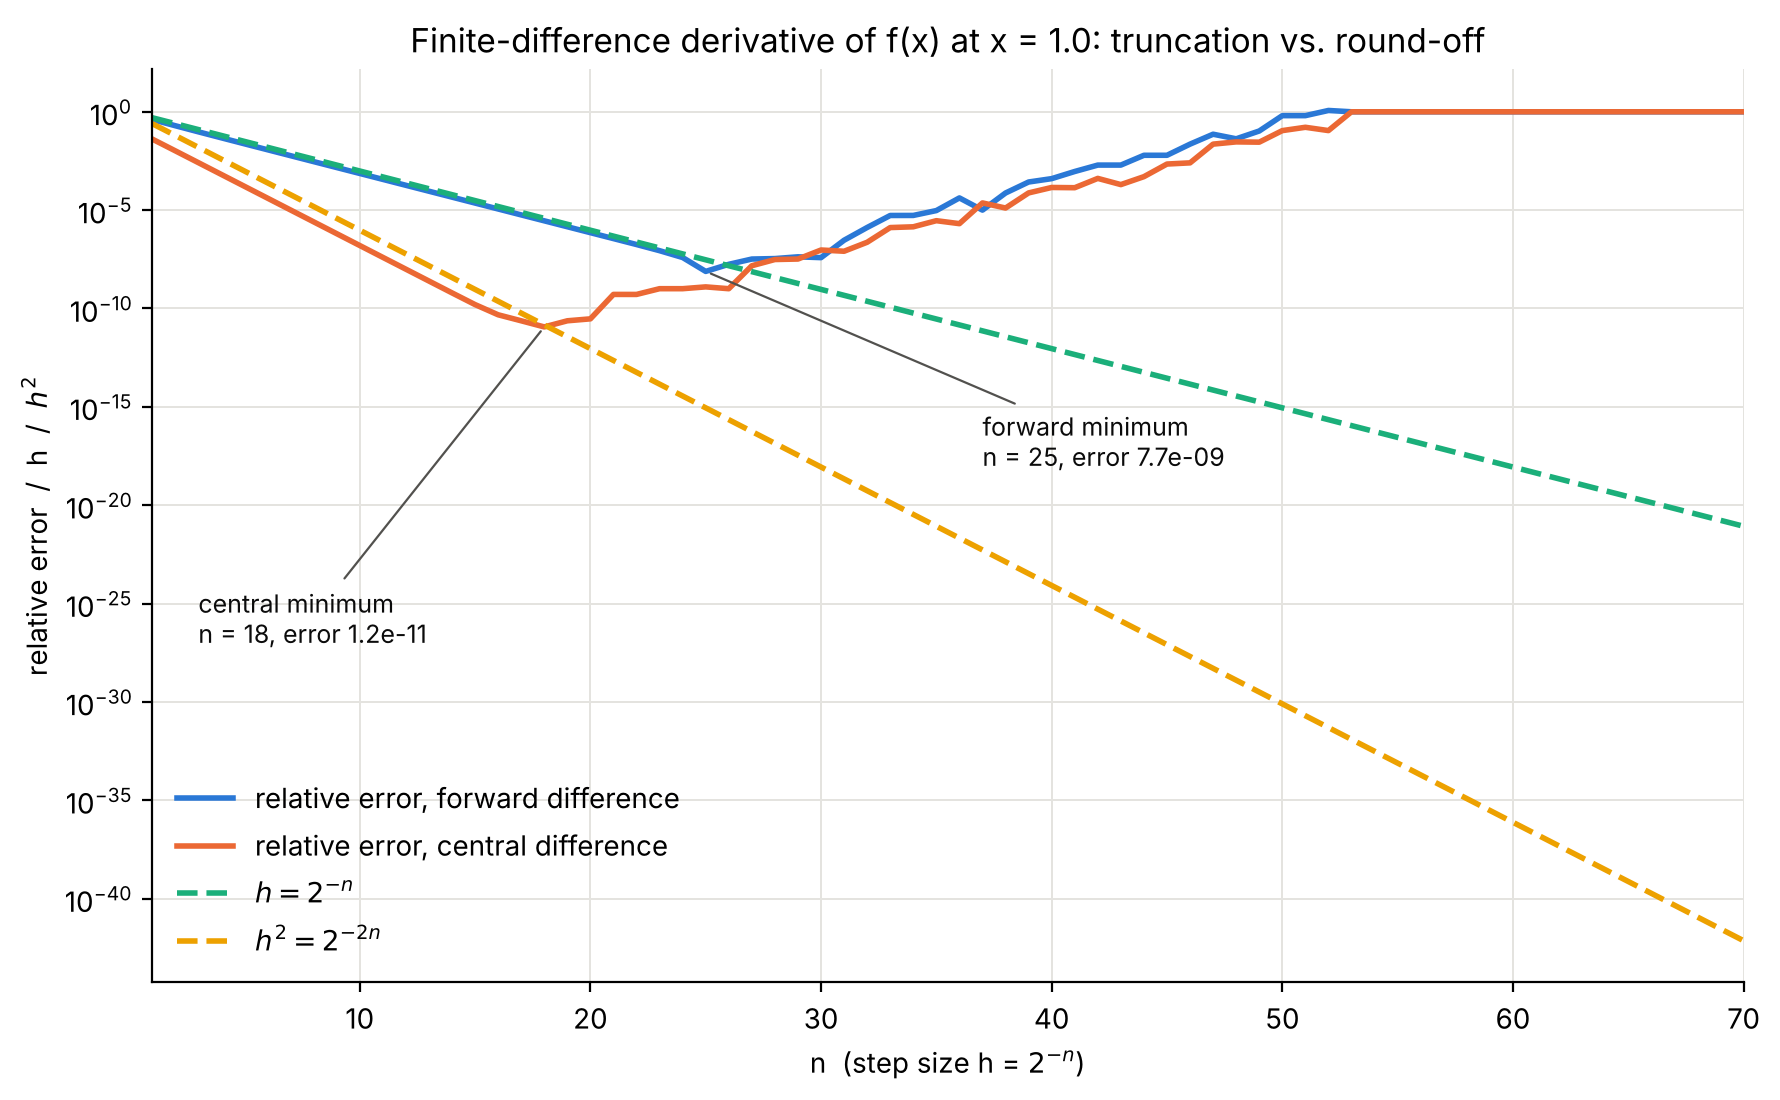

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return (2 * np.exp(1j * x) - 3 * np.exp(-1j * x)) / (-3j)


def df_exact(x):
    # d/dx: (2i exp(ix) + 3i exp(-ix)) / (-3i) = -(2 exp(ix) + 3 exp(-ix)) / 3
    return -(2 * np.exp(1j * x) + 3 * np.exp(-1j * x)) / 3


x0 = 1.0
n = np.arange(1, 71)
h = 2.0 ** (-n)

forward = (f(x0 + h) - f(x0)) / h
central = (f(x0 + h) - f(x0 - h)) / (2 * h)

exact = df_exact(x0)
err_forward = np.abs(forward - exact) / np.abs(exact)
err_central = np.abs(central - exact) / np.abs(exact)

best_f = np.argmin(err_forward)
best_c = np.argmin(err_central)

print(f"exact f'(1.0) = {exact:.15f}")
print(f"forward: minimum relative error {err_forward[best_f]:.3e} at n = {n[best_f]}")
print(f"central: minimum relative error {err_central[best_c]:.3e} at n = {n[best_c]}")
print(f"\n{'n':>3} {'h':>11} {'forward':>11} {'central':>11}")
for k in (1, 2, 4, 8, 12, 16, 18, 20, 24, 26, 28, 30, 36, 40, 44, 48, 50,
          51, 52, 53, 54, 55, 60, 70):
    i = k - 1
    print(f"{k:>3} {h[i]:>11.3e} {err_forward[i]:>11.3e} {err_central[i]:>11.3e}")

fig, ax = plt.subplots(figsize=(9, 5.6), dpi=200)
ax.semilogy(n, err_forward, color="#2a78d6", lw=2, label="relative error, forward difference")
ax.semilogy(n, err_central, color="#eb6834", lw=2, label="relative error, central difference")
ax.semilogy(n, h, color="#1baf7a", lw=2, ls="--", label=r"$h = 2^{-n}$")
ax.semilogy(n, h ** 2, color="#eda100", lw=2, ls="--", label=r"$h^2 = 2^{-2n}$")

ax.annotate(f"forward minimum\nn = {n[best_f]}, error {err_forward[best_f]:.1e}",
            xy=(n[best_f], err_forward[best_f]), xytext=(n[best_f] + 12, 1e-18),
            fontsize=9, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))
ax.annotate(f"central minimum\nn = {n[best_c]}, error {err_central[best_c]:.1e}",
            xy=(n[best_c], err_central[best_c]), xytext=(n[best_c] - 15, 1e-27),
            fontsize=9, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))

ax.set_xlabel("n  (step size h = $2^{-n}$)")
ax.set_ylabel("relative error  /  h  /  $h^2$")
ax.set_title("Finite-difference derivative of f(x) at x = 1.0: truncation vs. round-off")
ax.set_xlim(1, 70)
ax.grid(True, which="major", color="#e4e3df", lw=0.7)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("ps_4_ex_3c_plot.png")
plt.show()